# UFC Group Project
## Part 3
### Visualizations

In [1]:
import pandas as pd

df = pd.read_csv("ufc_fighters_clean.csv")

print(df.head())
print(df.columns)

     id                   name gender  weight_class    stance  height_in  \
0  2683          AJ Cunningham      M  Bantamweight  Orthodox       70.0   
1  2721     Baergeng Jieleyisi      M  Bantamweight  Orthodox       69.0   
2   280         Brian Kelleher      M  Bantamweight    Switch       66.0   
3  1312          Bryan Caraway      M  Bantamweight  Orthodox       68.0   
4  2670  Charalampos Grigoriou      M  Bantamweight  Orthodox       67.0   

   weight_lbs  reach_in  wins  losses  draws  ko_wins  sub_wins  \
0       136.0      71.0  11.0     5.0    0.0      4.0       4.0   
1       135.0      70.0  18.0     6.0    0.0      4.0      10.0   
2       136.0      66.0  24.0    16.0    0.0      8.0      10.0   
3       135.0      68.0  21.0    10.0    0.0      2.0      16.0   
4       136.0      67.5   8.0     5.0    0.0      6.0       0.0   

   decision_wins  total_fights   win_pct   win_style  reach_vs_class  
0            3.0          16.0  0.687500          KO             2.0 

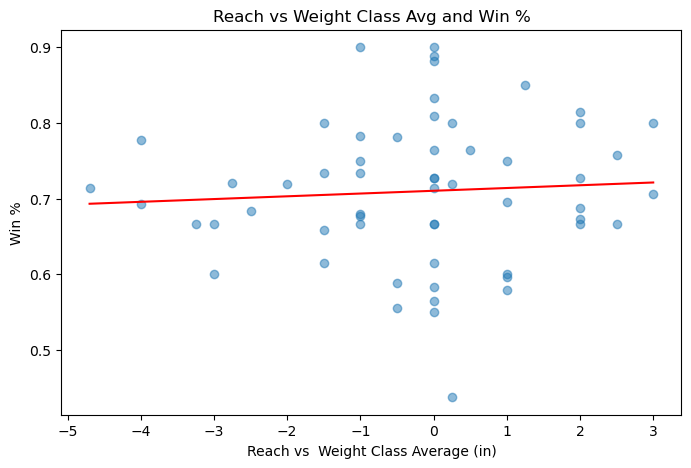

In [2]:
import matplotlib.pyplot as plt
import numpy as np

d = df[df["total_fights"] >= 5].dropna(subset=["reach_vs_class", "win_pct"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d["reach_vs_class"], d["win_pct"], alpha=0.5)

m, b = np.polyfit(d["reach_vs_class"], d["win_pct"], 1)
x = np.linspace(d["reach_vs_class"].min(), d["reach_vs_class"].max(), 100)
ax.plot(x, m * x + b, color='red')

ax.set_title("Reach vs Weight Class Avg and Win %")
ax.set_xlabel("Reach vs  Weight Class Average (in)")
ax.set_ylabel("Win %")
plt.show()

This visualization shows the relationship between a fighters reach compared to the rest of their weight class compared against their win pct. The trend line is slightly positive, indicating that fighters with longer reaches typically have higher win pcts compared to their peers with shorter reaches. 

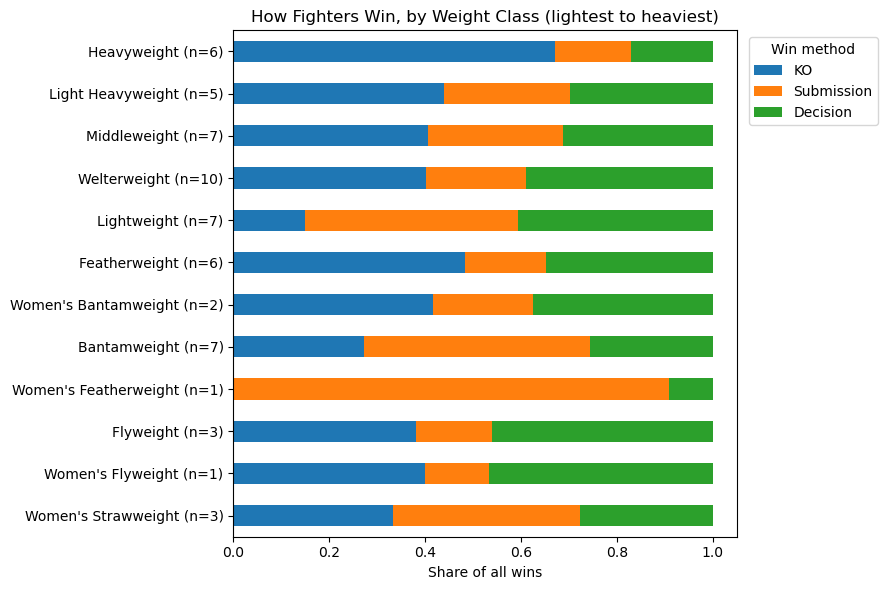

In [4]:
order = df.groupby("weight_class")["weight_lbs"].median().sort_values().index

totals = df.groupby("weight_class")[["ko_wins", "sub_wins", "decision_wins"]].sum().loc[order]
shares = totals.div(totals.sum(axis=1), axis=0)
shares.columns = ["KO", "Submission", "Decision"]

ax = shares.plot(kind="barh", stacked=True, figsize=(9, 6))

counts = df["weight_class"].value_counts()
ax.set_yticks(range(len(order)), [f"{wc} (n={counts[wc]})" for wc in order])
ax.set_xlabel("Share of all wins")
ax.set_ylabel("")
ax.set_title("How Fighters Win, by Weight Class (lightest to heaviest)")
ax.legend(title="Win method", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()


In this chart, we are analyzing which win methods are most common among each weight class. In the heavyweight class, ~70% of fights end in a knockout, this is the highest KO rate among all weight classes. Flyweight fights have the highest rate of ending in decision at just under 50%, while women's featherweight far and away exceeds the next closest submission win percentage, with over 90%. One thing to be considered, however, is the small sample size.  